In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
survival_counts = df["Survived"].value_counts()

print("Survival counts:")
print(survival_counts)

print("\nSurvival percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


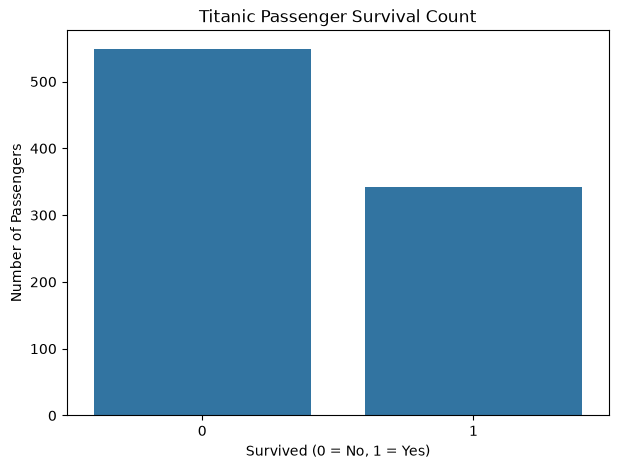

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

Survival rate by sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


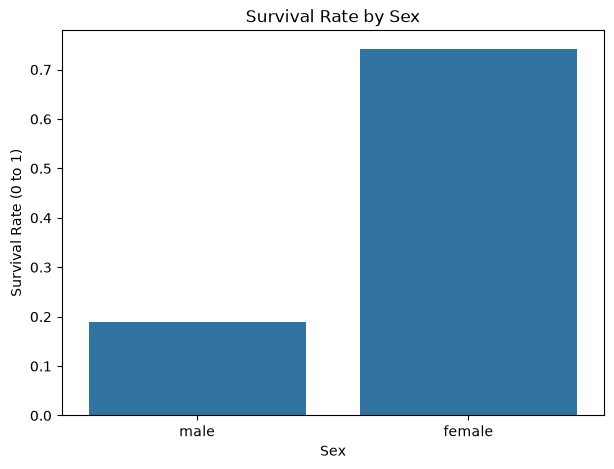

In [6]:
survival_by_sex = df.groupby("Sex", observed=True)["Survived"].mean() * 100

print("Survival rate by sex (%):")
print(survival_by_sex.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate (0 to 1)")

plt.show()

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


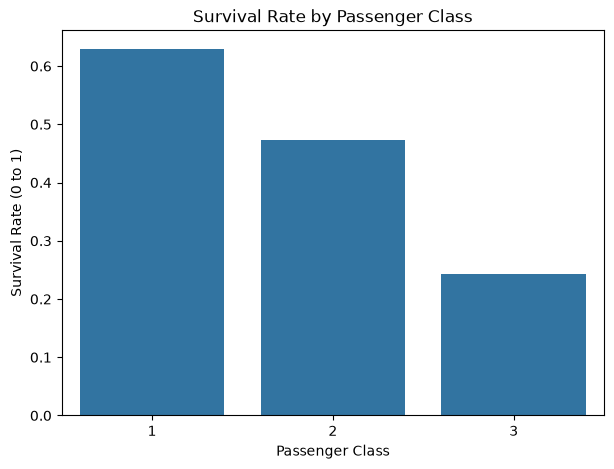

In [7]:
survival_by_class = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by passenger class (%):")
print(survival_by_class.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (0 to 1)")

plt.show()

Average age by survival status:
Survived
0    30.03
1    28.29
Name: Age, dtype: float64


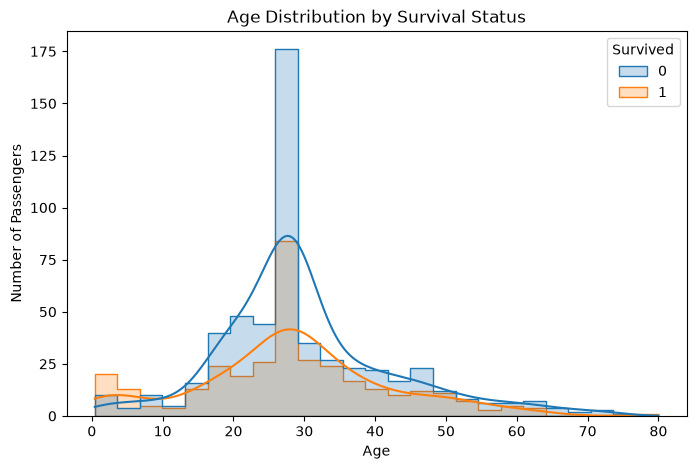

In [8]:
survival_by_age = df.groupby("Survived")["Age"].mean()

print("Average age by survival status:")
print(survival_by_age.round(2))

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=25,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

Survival rate by number of siblings/spouses (%):
SibSp
0    34.54
1    53.59
2    46.43
3    25.00
4    16.67
5     0.00
8     0.00
Name: Survived, dtype: float64


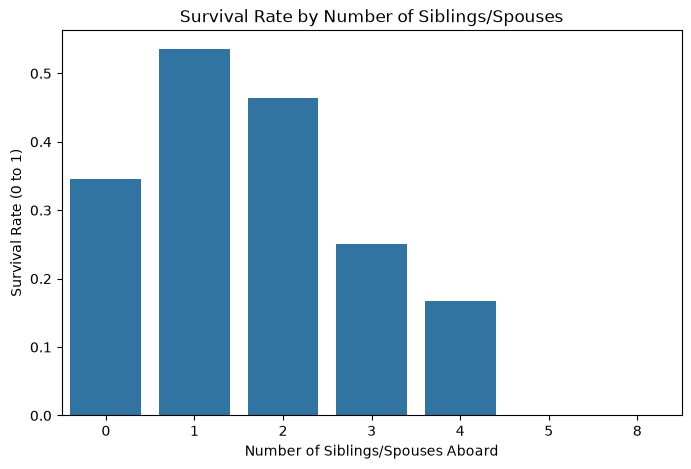

In [9]:
survival_by_sibsp = df.groupby("SibSp")["Survived"].mean() * 100

print("Survival rate by number of siblings/spouses (%):")
print(survival_by_sibsp.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="SibSp", y="Survived", errorbar=None)

plt.title("Survival Rate by Number of Siblings/Spouses")
plt.xlabel("Number of Siblings/Spouses Aboard")
plt.ylabel("Survival Rate (0 to 1)")

plt.show()

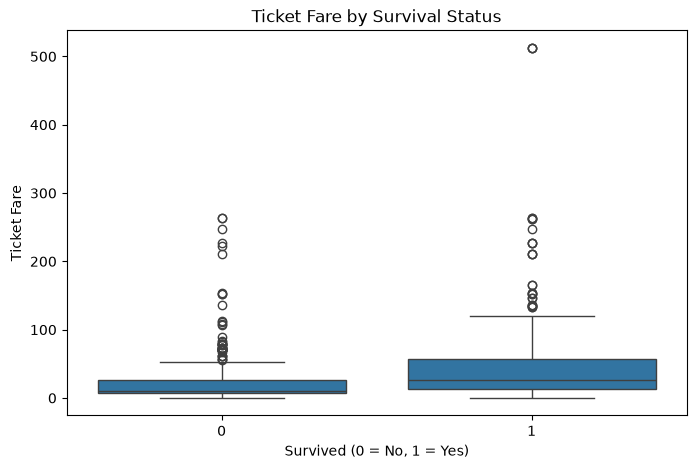

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Survived", y="Fare")

plt.title("Ticket Fare by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")

plt.show()

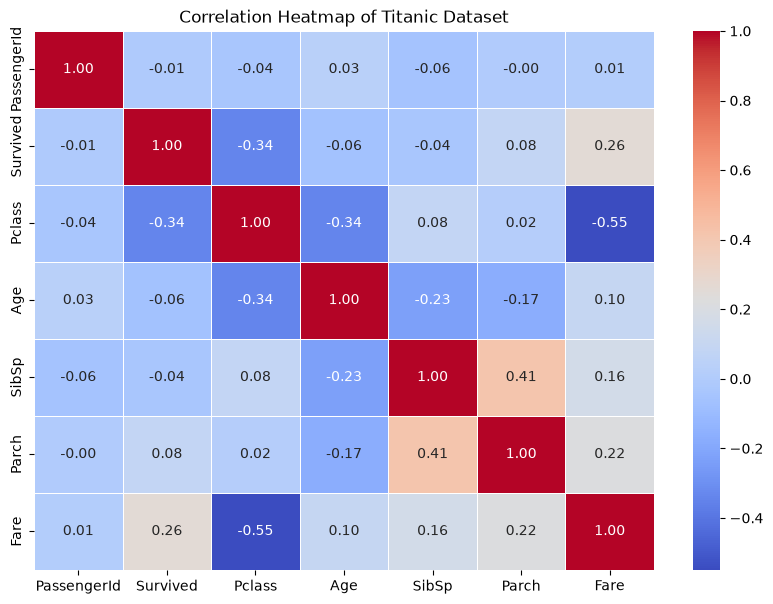

In [11]:
numeric_df = df.select_dtypes(include=["number"])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

In [12]:
class_analysis = df.groupby("Pclass").agg(
    Passenger_Count=("Survived", "count"),
    Survival_Rate=("Survived", "mean")
)

class_analysis["Survival_Rate"] = (
    class_analysis["Survival_Rate"] * 100
).round(2)

print(class_analysis)

        Passenger_Count  Survival_Rate
Pclass                                
1                   216          62.96
2                   184          47.28
3                   491          24.24


## Key Insights and Their Implications

The following insights are based on the statistical analysis and visualizations of the Titanic dataset. Each finding is connected to a possible machine-learning or decision-making implication.

In [13]:
print("1. Survival rate by sex (%):")
print((df.groupby("Sex", observed=True)["Survived"].mean() * 100).round(2))

print("\n2. Survival rate by passenger class (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\n3. Survival rate by family size (%):")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
print((df.groupby("FamilySize")["Survived"].mean() * 100).round(2))

print("\n4. Average age by survival status:")
print(df.groupby("Survived")["Age"].mean().round(2))

print("\n5. Median fare by survival status:")
print(df.groupby("Survived")["Fare"].median().round(2))

1. Survival rate by sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

2. Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

3. Survival rate by family size (%):
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64

4. Average age by survival status:
Survived
0    30.03
1    28.29
Name: Age, dtype: float64

5. Median fare by survival status:
Survived
0    10.5
1    26.0
Name: Fare, dtype: float64


### Insight 1: Survival Rates Differed by Sex

The analysis compares survival rates between male and female passengers. A substantial difference between these rates would indicate that sex is an informative feature for predicting survival.

**Model implication:** The `Sex` column should be considered as a candidate feature in a classification model. Its usefulness should be evaluated using validation data.

### Insight 2: Passenger Class Was Associated with Survival

Survival rates were compared across first-, second-, and third-class passengers. Differences between these groups can reveal an association between passenger class and survival.

**Model implication:** The `Pclass` column may improve survival predictions. Passenger class could also help decision-makers understand differences in outcomes between passenger groups.

### Insight 3: Family Size May Influence Survival Patterns

Family size was calculated using the number of siblings or spouses (`SibSp`) and parents or children (`Parch`), plus the passenger themselves. Survival rates were then compared across family sizes.

**Model implication:** The derived `FamilySize` feature may capture useful information that the original family-count columns do not represent individually. Its predictive value should be tested.

### Insight 4: Age May Be Associated with Survival

The average age of survivors was compared with the average age of non-survivors, and age distributions were visualized. Differences between the groups may indicate that age provides useful predictive information.

**Model implication:** The `Age` column could be included as a numerical feature. Since missing ages were replaced with the median during cleaning, this assumption should be documented when interpreting the results.

### Insight 5: Ticket Fare May Provide Predictive Information

Ticket fares were compared between survivors and non-survivors using a box plot and median statistics. Differences in the distributions may indicate an association between fare and survival.

**Model implication:** The `Fare` column may help a model distinguish between outcomes. Because fare may be related to passenger class, both features should be evaluated together rather than assuming they provide completely independent information.

### Overall Conclusion

The EDA examined the distributions and relationships of survival outcomes with sex, passenger class, age, family size, and ticket fare. These analyses identified candidate features for a future survival-prediction model.

The findings describe associations in the Titanic dataset and do not establish causation. Further model training and validation would be required to determine which features improve predictive performance.